In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("marketplace_raw.csv")

print("Dataset shape:", df.shape)
df.head()

Saving marketplace_raw.csv to marketplace_raw (1).csv
Dataset shape: (1801, 20)


,global_id,student_id,source_file,item_id,title,description,category,age,condition,price,currency,item_photo,unnamed_0,unnamed_1,unnamed_2,unnamed_9,unnamed_10,link,Unnamed: 18,image_path
0,1,1210482,1210482.csv,1,Tesla Model 3,"standard range with 21,867 miles on it. Deep B...",Cars,4,4,28868,dollar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,images/0001_1210482.jpg
1,2,1210482,1210482.csv,2,Mercedes-Benz AMG GT 63 4MATIC,22025 miles on it. Obsidian Black Metallic ext...,Cars,7,4,79412,dollar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,images/0002_1210482.jpg
2,3,1210482,1210482.csv,3,Lexus LX 600 Luxury,11956 miles on it. Eminent White Pearl exterio...,Cars,3,5,90451,dollar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,images/0003_1210482.jpg
3,4,1210482,1210482.csv,4,Crate & Barrel Unwind Green Velvet 2 Seater Sofa,Brand: Crate & Barrel. Collection: Unwind. Con...,Furniture,3,4,750,dollar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,images/0004_1210482.jpg
4,5,1210482,1210482.csv,5,Drexel Heritage 1980s Postmodern Curved Sofa F...,Brand: Drexel. Condition: Used - Age-worn: Has...,Furniture,40,2,450,dollar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,images/0005_1210482.jpg


In [2]:
assessment_df = df.copy()

missing_tokens = [
    "",
    " ",
    "NA",
    "N/A",
    "na",
    "n/a",
    "NULL",
    "null",
    "None",
    "none"
]

assessment_df = assessment_df.replace(missing_tokens, pd.NA)

missing_count = assessment_df.isna().sum()

missing_percentage = (
    assessment_df.isna().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": missing_percentage
})

# Show ALL columns, including columns with 0 missing values
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
Unnamed: 18,1801,100.00
unnamed_1,1801,100.00
unnamed_2,1801,100.00
unnamed_9,1801,100.00
unnamed_0,1801,100.00
unnamed_10,1800,99.94
link,1786,99.17
age,374,20.77
item_photo,90,5.00
price,32,1.78


Missing values were identified for every column in the integrated dataset, and the percentage of missing values was calculated relative to the total number of observations.

The highest proportion of missing data was found in the `age` column, with 374 missing values (20.77%). The `item_photo` column contained 90 missing values (5.00%), followed by `price` with 32 missing values (1.78%) and `currency` with 23 missing values (1.28%).

Both `condition` and `item_id` contained 15 missing values (0.83%), while `description` and `category` each contained 1 missing value (0.06%).

Several non-standard auxiliary columns, such as `unnamed_0`, `unnamed_1`, `unnamed_2`, `unnamed_9`, `unnamed_10`, and `link`, contained very high percentages of missing values. These columns originated from individual student submissions and will be handled during the cleaning stage.

Columns with no missing values were also included in the summary table to provide a complete column-by-column assessment.

In [3]:
# Duplicate full records
duplicate_records = df.duplicated().sum()

# Duplicate item IDs alone - ignore missing IDs
duplicate_item_ids = (
    df["item_id"]
    .dropna()
    .duplicated()
    .sum()
)

# Duplicate item IDs within the same student - ignore missing IDs
duplicate_student_item_ids = (
    df.dropna(subset=["item_id"])
      .duplicated(subset=["student_id", "item_id"])
      .sum()
)

print("Duplicate full records:", duplicate_records)
print("Duplicate item IDs alone:", duplicate_item_ids)
print("Duplicate (student_id + item_id):", duplicate_student_item_ids)

Duplicate full records: 0
Duplicate item IDs alone: 1620
Duplicate (student_id + item_id): 0


Duplicate records and item IDs were assessed in the integrated dataset.

No fully duplicated records were found. Although 1,620 duplicate `item_id` values were detected when `item_id` was checked alone, this is expected because different students use the same item numbering scheme, such as `item_001`, `item_002`, and so on.

To identify meaningful duplicate item IDs, the combination of `student_id` and `item_id` was checked. No duplicate `(student_id, item_id)` combinations were found, indicating that no student has the same item ID repeated within their own submission.


In [4]:
print("Categories:")
print(df["category"].value_counts(dropna=False))

print("\nCurrencies:")
print(df["currency"].value_counts(dropna=False))

Categories:
category
Electronics                    361
Furniture                      178
Kitchen and household items    173
Clothing and accessories       169
Books                          141
                              ... 
Microwave Ovens                  1
Strollers                        1
Acoustic Guitars                 1
Electric Bicycles                1
Phone Accessories                1
Name: count, Length: 133, dtype: int64

Currencies:
currency
ILS        1105
USD         375
GBP          49
NIS          48
EUR          23
ils          21
NaN          21
CHF          19
Shekel       15
₪            15
Unknown      12
JOD          10
 USD         10
dollar       10
AED          10
usd           9
SGD           7
ILS           7
shekel        6
EGP           6
 GBP          5
USD           5
SAR           4
TWD           2
              2
LYD           1
IQD           1
SEK           1
INR           1
AUD           1
Name: count, dtype: int64


In [5]:
clean_df = df.copy()

def clean_currency(x):
    if pd.isna(x):
        return pd.NA

    x = str(x).strip().lower()

    currency_map = {
        "ils": "ILS",
        "nis": "ILS",
        "shekel": "ILS",
        "₪": "ILS",

        "usd": "USD",
        "dollar": "USD",
        "$": "USD",

        "eur": "EUR",
        "gbp": "GBP",
        "chf": "CHF",
        "jod": "JOD",
        "aed": "AED",
        "sgd": "SGD",
        "sar": "SAR",
        "twd": "TWD",
        "lyd": "LYD",
        "iqd": "IQD",
        "sek": "SEK",
        "inr": "INR",
        "aud": "AUD",
        "egp": "EGP"
    }

    if x in ["unknown", "nan", "none", "n/a", "na", ""]:
        return pd.NA

    return currency_map.get(x, x.upper())

clean_df["currency"] = clean_df["currency"].apply(clean_currency)

print(clean_df["currency"].value_counts(dropna=False))

currency
ILS     1217
USD      409
GBP       54
<NA>      35
EUR       23
CHF       19
AED       10
JOD       10
SGD        7
EGP        6
SAR        4
TWD        2
LYD        1
IQD        1
SEK        1
AUD        1
INR        1
Name: count, dtype: int64


In [6]:
def clean_category(x):
    if pd.isna(x):
        return pd.NA

    x = str(x).strip()
    key = x.lower().replace(":", "").strip()

    category_map = {
        "electronics": "Electronics",
        "electronics and tech": "Electronics",
        "electronics and accessories": "Electronics",

        "furniture": "Furniture",

        "clothing and accessories": "Clothing and Accessories",
        "clothing & accessories": "Clothing and Accessories",
        "clothing": "Clothing and Accessories",
        "clothes": "Clothing and Accessories",

        "sports equipment": "Sports Equipment",
        "sports equipments": "Sports Equipment",
        "sports": "Sports Equipment",

        "toys and games": "Toys and Games",
        "toys & games": "Toys and Games",
        "games and toys": "Toys and Games",
        "toys": "Toys and Games",
        "games": "Toys and Games",

        "musical instruments": "Musical Instruments",
        "musical instrument": "Musical Instruments",

        "kitchen and household items": "Kitchen and Household Items",
        "kitchen and household item": "Kitchen and Household Items",
        "kitchen and household": "Kitchen and Household Items",
        "kitchen & household": "Kitchen and Household Items",
        "kitchen & household items": "Kitchen and Household Items",
        "kitchen items": "Kitchen and Household Items",
        "kitchen": "Kitchen and Household Items",

        "other used products": "Other Used Products",
        "other": "Other Used Products",

        "home decor": "Home Decor",
        "home décor": "Home Decor",
        "decor": "Home Decor",
        "art and decor": "Home Decor",

        "personal care": "Personal Care",
        "health & personal care": "Personal Care",
        "beauty and personal care": "Personal Care"
    }

    return category_map.get(key, x)

clean_df["category"] = clean_df["category"].apply(clean_category)

print("Categories before:", df["category"].nunique(dropna=True))
print("Categories after:", clean_df["category"].nunique(dropna=True))

Categories before: 132
Categories after: 75


In [7]:
text_columns = ["title", "description", "category", "currency", "item_id", "item_photo"]

for col in text_columns:
    if col in clean_df.columns:
        clean_df[col] = (
            clean_df[col]
            .astype("string")
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )


In [8]:
print("Final categories:")
print(clean_df["category"].value_counts(dropna=False))

print("\nFinal currencies:")
print(clean_df["currency"].value_counts(dropna=False))

Final categories:
category
Electronics                     384
Clothing and Accessories        253
Kitchen and Household Items     246
Furniture                       188
Books                           143
                               ... 
Refrigerators                     1
Dining Tables and Chair Sets      1
Electric Bicycles                 1
Acoustic Guitars                  1
Phone Accessories                 1
Name: count, Length: 76, dtype: Int64

Final currencies:
currency
ILS     1217
USD      409
GBP       54
<NA>      35
EUR       23
CHF       19
AED       10
JOD       10
SGD        7
EGP        6
SAR        4
TWD        2
LYD        1
IQD        1
SEK        1
AUD        1
INR        1
Name: count, dtype: Int64


Inconsistencies in category names, currency formats, and text representations were standardized.

Category labels representing the same category but differing in capitalization, spacing, punctuation, singular/plural forms, or equivalent wording were mapped to a consistent representation. This reduced the number of raw category representations from 132 to 75 distinct non-missing category labels. Semantically different categories were preserved rather than being arbitrarily merged into broader groups.

Currency values were standardized to consistent three-letter currency codes. For example, `NIS`, `Shekel`, `shekel`, and the shekel symbol were standardized to `ILS`, while `usd` and `dollar` were standardized to `USD`. Unknown or missing currency representations were converted to missing values.

Text fields were also standardized by removing leading and trailing whitespace and collapsing repeated spaces.

## 3.4 Invalid Values

The numeric fields (`price`, `age`, `condition`) were stored as text during integration, so they are converted to numbers first. The original text is kept in `price_raw`, `age_raw` and `condition_raw`, and values that cannot be parsed are listed, not silently dropped.

In [9]:
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Keep the original text; always parse FROM the raw copy so the cell can be re-run safely
for col in ["price", "age", "condition"]:
    if f"{col}_raw" not in clean_df.columns:
        clean_df[f"{col}_raw"] = clean_df[col]

AR_DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩٫٬", "0123456789.,")

def to_number(x):
    """'1,200 NIS' -> 1200 | '٣٠٠' -> 300 | '2-3' -> 2.5 | 'abc' -> NaN"""
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower().translate(AR_DIGITS)
    s = re.sub(r"(?<=\d),(?=\d{3}\b)", "", s)      # thousands separator: 1,200 -> 1200
    s = s.replace(",", ".")                           # decimal comma: 2,5 -> 2.5
    m = re.search(r"(\d+(?:\.\d+)?)\s*(?:-|–|to)\s*(\d+(?:\.\d+)?)", s)
    if m:                                             # range -> midpoint
        return (float(m[1]) + float(m[2])) / 2
    m = re.search(r"-?\d+(?:\.\d+)?", s)
    return float(m.group()) if m else np.nan

def parse_age(x):
    """Age in YEARS. '6 months' -> 0.5"""
    val = to_number(x)
    if pd.isna(val):
        return np.nan
    s = str(x).lower()
    if re.search(r"month|شهر|أشهر", s): return val / 12
    if re.search(r"week|أسبوع", s):     return val / 52
    if re.search(r"day|يوم", s):        return val / 365
    return val

def parse_condition(x):
    """'4/5' -> 4"""
    if pd.isna(x):
        return np.nan
    return to_number(str(x).split("/")[0])

clean_df["price"]     = clean_df["price_raw"].map(to_number)
clean_df["age"]       = clean_df["age_raw"].map(parse_age)
clean_df["condition"] = clean_df["condition_raw"].map(parse_condition)

# Values that existed in the file but could not be converted -> inspect them manually
for col in ["price", "age", "condition"]:
    bad = clean_df[clean_df[f"{col}_raw"].notna() & clean_df[col].isna()]
    print(f"{col}: {len(bad)} non-numeric value(s) could not be parsed")
    if len(bad):
        display(bad[["student_id", "item_id", f"{col}_raw"]].head(20))

price: 4 non-numeric value(s) could not be parsed


,student_id,item_id,price_raw
287,1220429,item_003,
296,1220429,item_012,
297,1220429,item_013,
1644,1231412,item_009,unknown


age: 11 non-numeric value(s) could not be parsed


,student_id,item_id,age_raw
188,1220226,item_009,Unknown
301,1220433,2,Unkown
304,1220433,5,Unkown
305,1220433,6,Unkown
313,1220433,14,Unkown
314,1220433,15,Unkown
1041,1230318,item_007,unkown
1042,1230318,item_008,unkown
1431,1230834,item_006,Unkown
1433,1230834,item_008,Unkown


condition: 20 non-numeric value(s) could not be parsed


,student_id,item_id,condition_raw
224,1220257,item_015,Unknown
240,1220352,item_001,good
241,1220352,item_002,good
242,1220352,item_003,poor
243,1220352,item_004,good
244,1220352,item_005,good
245,1220352,item_006,good
246,1220352,item_007,good
247,1220352,item_008,good
248,1220352,item_009,good


In [10]:
# Make sure numeric columns are actually numeric
clean_df["price"] = pd.to_numeric(clean_df["price"], errors="coerce")
clean_df["age"] = pd.to_numeric(clean_df["age"], errors="coerce")
clean_df["condition"] = pd.to_numeric(clean_df["condition"], errors="coerce")

AGE_MAX = 100

invalid = pd.DataFrame({
    "negative_price": clean_df["price"] < 0,
    "zero_price": clean_df["price"] == 0,
    "negative_age": clean_df["age"] < 0,
    "unreasonable_age": clean_df["age"] > AGE_MAX,
    "condition_out_of_range":
        (clean_df["condition"] < 1) | (clean_df["condition"] > 5),
})

invalid_summary = pd.DataFrame({
    "count": invalid.sum(),
    "percentage": (invalid.mean() * 100).round(2),
})

display(invalid_summary)

# Look at invalid rows before changing anything
any_invalid = invalid.any(axis=1)

display(
    clean_df.loc[
        any_invalid,
        [
            "global_id",
            "student_id",
            "item_id",
            "title",
            "category",
            "price_raw",
            "currency",
            "age_raw",
            "condition_raw"
        ]
    ]
)

,count,percentage
negative_price,0,0.00
zero_price,1,0.06
negative_age,0,0.00
unreasonable_age,8,0.44
condition_out_of_range,1,0.06


,global_id,student_id,item_id,title,category,price_raw,currency,age_raw,condition_raw
77,78,1212312,item_003,Edwardian 1911 Drafting Set Hull School Prize ...,Stationery and Office Supplies,55.00,GBP,115,4
122,123,1220064,item_003,Electric cooker with two ovens,Kitchen and Household Items,0,GBP,NaN,4
487,488,1221305,item_008,Edwardian platinum sapphire and diamond ring,Clothing and Accessories,5259.8,USD,116,5
711,712,1230014,item_007,1850-1885 S. Kirk & Son Co. Sterling Silver Be...,Kitchen and Household Items,360,USD,126,2
719,720,1230014,item_015,Fine Genuine Handmade Middle Eastern Pictorial...,Other Used Products,6495,USD,126,4
795,796,1230099,item_001,Large Red Copper Teapot,Kitchen and Household Items,400,ILS,150.0,5
821,822,1230100,012,Used Natural History of Man Book,Books,140,ILS,102,4
1127,1128,1230482,item_003,"Antique Hand-Painted Dome-Top Wooden Box, Earl...",Other Used Products,195,USD,216,3
1163,1164,1230501,item_009,Used play station 5,Toys and Games,350,USD,NaN,9
1330,1331,1230696,item_010,Antique Salter’s,Kitchen and Household Items,79,USD,106,3


Prices were converted to numbers (thousands separators, currency symbols and Arabic digits removed). Ages were converted to years. Negative or zero prices (1 row), negative ages or ages above 100 years (8 rows), and condition scores outside 1–5 (1 row) were treated as invalid. They were replaced with missing values instead of 0 and the rows were kept, because the other fields of those items are still valid. The original text is preserved in `price_raw`, `age_raw`, `condition_raw`, and flag columns (`invalid_price`, `invalid_age`, `invalid_condition`) record which values were changed.

In [11]:
# Handling: invalid values are replaced with NaN (NOT with 0, and rows are NOT deleted),
# so the rest of the item information is still usable. The original text stays in *_raw.
clean_df["invalid_price"]     = invalid["negative_price"] | invalid["zero_price"]
clean_df["invalid_age"]       = invalid["negative_age"] | invalid["unreasonable_age"]
clean_df["invalid_condition"] = invalid["condition_out_of_range"]

clean_df.loc[clean_df["invalid_price"],     "price"]     = np.nan
clean_df.loc[clean_df["invalid_age"],       "age"]       = np.nan
clean_df.loc[clean_df["invalid_condition"], "condition"] = np.nan

print("Set to NaN -> price:", clean_df["invalid_price"].sum(),
      "| age:", clean_df["invalid_age"].sum(),
      "| condition:", clean_df["invalid_condition"].sum())

# Non-integer conditions inside 1-5 (e.g. 3.5) are kept; just report them
print("Non-integer condition scores kept:",
      (clean_df["condition"].notna() & (clean_df["condition"] % 1 != 0)).sum())

Set to NaN -> price: 1 | age: 8 | condition: 1
Non-integer condition scores kept: 0


**Invalid values – decisions.**
Prices were converted to numbers (thousands separators, currency symbols and Arabic digits removed). Ages were converted to years. Negative or zero prices (XX rows), negative ages or ages above 100 years (XX rows), and condition scores outside 1–5 (XX rows) were treated as invalid. They were replaced with missing values instead of 0 and the rows were kept, because the other fields of those items are still valid. The original text is preserved in `price_raw`, `age_raw`, `condition_raw`, and flag columns (`invalid_price`, `invalid_age`, `invalid_condition`) record which values were changed.

## 3.5 Outliers

Prices are recorded in different currencies, so raw prices cannot be compared (10 USD is not 10 ILS). A comparable column `price_ils` is created with approximate fixed exchange rates. This is an analysis helper only; the original `price` and `currency` are unchanged.

In [12]:
# Approximate rates to ILS - an assumption, edit if you want different values
RATES_TO_ILS = {
    "ILS": 1.0, "USD": 3.6, "EUR": 4.2, "GBP": 4.8, "JOD": 5.1, "CHF": 4.5,
    "AED": 0.98, "SAR": 0.96, "EGP": 0.075, "SGD": 2.8, "TWD": 0.11,
    "LYD": 0.75, "IQD": 0.0027, "SEK": 0.37, "INR": 0.043, "AUD": 2.4,
}

print("Currency counts:")
print(clean_df["currency"].value_counts(dropna=False))
unknown_cur = set(clean_df["currency"].dropna().unique()) - set(RATES_TO_ILS)
print("Currencies without a rate:", unknown_cur or "none")

clean_df["price_ils"] = clean_df["price"] * clean_df["currency"].map(RATES_TO_ILS)
print("Rows with price but no price_ils (missing/unknown currency):",
      (clean_df["price"].notna() & clean_df["price_ils"].isna()).sum())

Currency counts:
currency
ILS     1217
USD      409
GBP       54
<NA>      35
EUR       23
CHF       19
AED       10
JOD       10
SGD        7
EGP        6
SAR        4
TWD        2
LYD        1
IQD        1
SEK        1
AUD        1
INR        1
Name: count, dtype: Int64
Currencies without a rate: none
Rows with price but no price_ils (missing/unknown currency): 10


Price (ILS) fences: 0.5 - 51245.4
price_outlier
normal    1730
<NA>        44
high        26
low          1
Name: count, dtype: int64 

Age fences (years): 0.0 - 16.0
age_outlier
normal    1256
<NA>       393
high       152
Name: count, dtype: int64


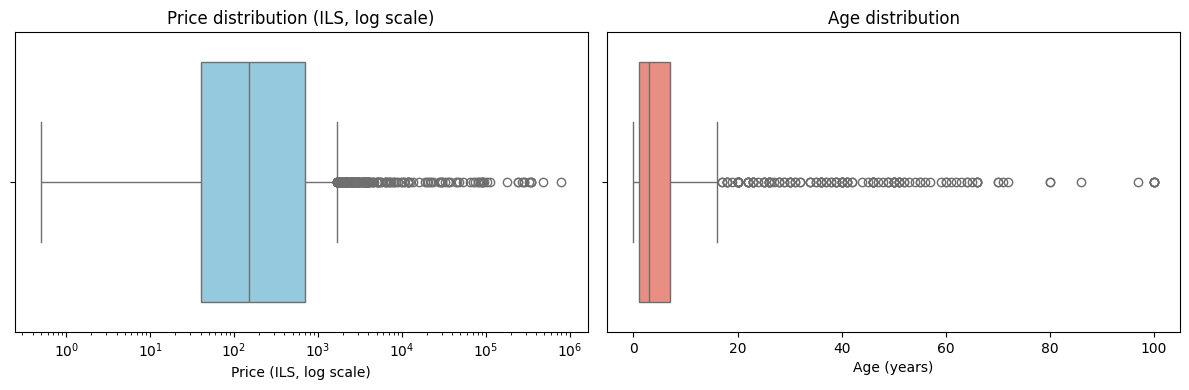

In [13]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# Prices are strongly right-skewed -> IQR on log(price); ages are used as they are
p = clean_df["price_ils"].where(clean_df["price_ils"] > 0)
lo, hi = np.exp(iqr_bounds(np.log(p.dropna())))
a_lo, a_hi = iqr_bounds(clean_df["age"].dropna())
a_lo = max(a_lo, 0)

clean_df["price_outlier"] = np.select([p < lo, p > hi], ["low", "high"], default="normal")
clean_df.loc[p.isna(), "price_outlier"] = pd.NA
clean_df["age_outlier"] = np.select([clean_df["age"] < a_lo, clean_df["age"] > a_hi], ["low", "high"], default="normal")
clean_df.loc[clean_df["age"].isna(), "age_outlier"] = pd.NA

print(f"Price (ILS) fences: {lo:.1f} - {hi:.1f}")
print(clean_df["price_outlier"].value_counts(dropna=False), "\n")
print(f"Age fences (years): {a_lo:.1f} - {a_hi:.1f}")
print(clean_df["age_outlier"].value_counts(dropna=False))

# How far is each price from the typical price of its own category?
clean_df["price_vs_category_median"] = (
    clean_df["price_ils"] / clean_df.groupby("category")["price_ils"].transform("median")
).round(2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=clean_df["price_ils"], ax=ax[0], color="skyblue")
ax[0].set_xscale("log")
ax[0].set_title("Price distribution (ILS, log scale)")
ax[0].set_xlabel("Price (ILS, log scale)")
sns.boxplot(x=clean_df["age"], ax=ax[1], color="salmon")
ax[1].set_title("Age distribution")
ax[1].set_xlabel("Age (years)")
plt.tight_layout()
plt.show()

In [14]:
# Investigate before deciding: are these real items (car, laptop, antique) or typing mistakes?
cols = ["global_id", "student_id", "title", "category", "condition",
        "price_raw", "currency", "price_ils", "price_vs_category_median", "age_raw"]

print("Highest prices")
display(clean_df.nlargest(15, "price_ils")[cols])
print("Lowest prices")
display(clean_df.nsmallest(15, "price_ils")[cols])

print("Highest ages")
display(clean_df.nlargest(15, "age")[["global_id", "student_id", "title", "category", "age_raw", "age", "condition"]])

Highest prices


,global_id,student_id,title,category,condition,price_raw,currency,price_ils,price_vs_category_median,age_raw
1376,1377,1230746,chicken farm,agriculture,4.0,800000,ILS,800000.0,1.00,NaN
1325,1326,1230696,Vintage 1954 Fender Stratocaster Sunburst Soli...,Musical Instruments,3.0,135000,USD,486000.0,845.22,72
307,308,1220433,2022 BMW 5 Series 545e,Cars,4.0,"350,000",ILS,350000.0,1.36,4
816,817,1230100,Used BMW 545e xDrive 2022,Vehicles,4.0,350000,ILS,350000.0,9.72,4
1375,1376,1230746,bmw car,cars,5.0,350000,ILS,350000.0,5.00,4
2,3,1210482,Lexus LX 600 Luxury,Cars,5.0,90451,USD,325623.6,1.26,3
1,2,1210482,Mercedes-Benz AMG GT 63 4MATIC,Cars,4.0,79412,USD,285883.2,1.11,7
1234,1235,1230567,Picarzo Pianos,Musical Instruments,3.0,79000,USD,284400.0,494.61,26.5
308,309,1220433,Mercedes-Benz GLS 400 2018,Cars,3.0,"270,000",ILS,270000.0,1.05,8
310,311,1220433,2024 Jeep Wrangler Rubicon X 4xe,Cars,4.0,"245,000",ILS,245000.0,0.95,2


Lowest prices


,global_id,student_id,title,category,condition,price_raw,currency,price_ils,price_vs_category_median,age_raw
1344,1345,1230703,Blue Ink Pen with Metal Clip,Stationery,2.0,0.5,ILS,0.50,0.08,0.08
162,163,1220161,Beige Tealight Candle in Aluminum Cup,Kitchen and Household Items,5.0,1,ILS,1.00,0.01,1
1336,1337,1230703,Plastic Armchair,Furniture,1.0,1,ILS,1.00,0.00,6
1058,1059,1230329,Bent spoon,Kitchen and Household Items,2.0,0.5,USD,1.80,0.02,5
116,117,1220031,Small Phillips Screwdriver,Tools,5.0,2,ILS,2.00,0.04,2
161,162,1220161,Orbit Mercury Blue Pen,Other Used Products,4.0,2,ILS,2.00,0.01,1
808,809,1230099,Brown Teddy Bear,Toys and Games,3.0,2,ILS,2.00,0.03,1.0
222,223,1220257,إيضاح المدارك في الإفصاح عن العوائق - Arabic Book,Books,4.0,30,EGP,2.25,0.09,2
158,159,1220161,Stainless Steel Dinner Fork,Kitchen and Household Items,3.0,3,ILS,3.00,0.03,5
166,167,1220168,Small White Light Bulb,Electronics,4.0,3,ILS,3.00,0.01,1.2


Highest ages


,global_id,student_id,title,category,age_raw,age,condition
306,307,1220433,The Natural History of Man,Books,100,100.0,3.0
485,486,1221305,Vintage Wm. A. Rogers silverplate serving spoo...,Kitchen and Household Items,100,100.0,2.0
718,719,1230014,Antique German Silver Mesh Purse / Evening Bag...,Clothing and Accessories,100,100.0,4.0
798,799,1230099,Charcoal Iron,Kitchen and Household Items,100.0,100.0,4.0
1333,1334,1230696,Vintage Chanel necklace,Clothing and Accessories,100,100.0,5.0
639,640,1222148,Art Deco Brooch Sterling Silver Marcasite Blac...,Clothing and Accessories,97,97.0,4.0
1331,1332,1230696,Vintage brass Scales of Justice beam balance s...,Kitchen and Household Items,86,86.0,3.0
712,713,1230014,Tiffany and Co Olympian Pattern Sterling Silve...,Kitchen and Household Items,80,80.0,3.0
716,717,1230014,Pristine 1940s Japanese Micro-Beaded Evening P...,Clothing and Accessories,80,80.0,5.0
1325,1326,1230696,Vintage 1954 Fender Stratocaster Sunburst Soli...,Musical Instruments,72,72.0,3.0


In [15]:
# Decision: NOTHING is removed automatically. Outliers stay in the data and are only flagged.
# Only if a row is clearly a typing mistake after checking the tables above (e.g. 5000000 for a mug),
# put its global_id here -> its price is set to NaN (the item itself is kept).
CONFIRMED_PRICE_ERRORS = []     # e.g. [123, 456]

mask = clean_df["global_id"].isin(CONFIRMED_PRICE_ERRORS)
clean_df.loc[mask, ["price", "price_ils"]] = np.nan
clean_df.loc[mask, "price_outlier"] = pd.NA
print("Prices removed after manual verification:", mask.sum())

Prices removed after manual verification: 0


**Outliers – decisions.**
Prices were converted to ILS for comparison and outliers were detected with the IQR rule (1.5 × IQR) on log-price, because prices are right-skewed. Ages used the IQR rule on the original scale. The flagged high prices (26 items) were inspected one by one: most appeared to be legitimately expensive items, so they were retained and only flagged in `price_outlier`. One low-price outlier was identified and retained because it was still plausible. Outliers were not removed automatically, and no price values were confirmed as data-entry errors after manual verification.

**Missing values – decisions.**  
Missing `age`, `price`, `condition`, and `currency` values were left as missing rather than replaced with 0 or guessed, so statistics are computed using the available values. Auxiliary columns created by student files (`unnamed_*`, `link`) contain no meaningful item information and were dropped from the cleaned file.

In [16]:
# Final cleaned dataset
drop_cols = [c for c in clean_df.columns
             if str(c).lower().startswith("unnamed") or c in ("link", "")
             or str(c).endswith("_raw")]
final_df = clean_df.drop(columns=drop_cols)

final_df.to_csv("marketplace_cleaned.csv", index=False, encoding="utf-8-sig")
print("Saved marketplace_cleaned.csv ->", final_df.shape)

try:                                   # Colab: download the file
    from google.colab import files
    files.download("marketplace_cleaned.csv")
except ImportError:
    pass

Saved marketplace_cleaned.csv -> (1801, 20)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:

# 1. Inspect all high-price outliers
high_prices = clean_df[
    clean_df["price_outlier"] == "high"
].sort_values("price_ils", ascending=False)

print("Total high-price outliers:", len(high_prices))

display(high_prices[[
    "global_id", "student_id", "title", "category",
    "price_raw", "currency", "price_ils",
    "price_vs_category_median"
]])


# 2. Inspect all unusually old items
high_ages = clean_df[
    clean_df["age_outlier"] == "high"
].sort_values("age", ascending=False)

print("Total high-age outliers:", len(high_ages))

display(high_ages[[
    "global_id", "title", "category",
    "age_raw", "age", "condition"
]])


# 3. Inspect ages above 100 years separately
very_old = clean_df[clean_df["age_raw"].notna()].copy()
very_old = very_old[very_old["age"] > 100]

print("Items older than 100 years:", len(very_old))

display(very_old[[
    "global_id", "title", "category",
    "age_raw", "age", "condition"
]])


Total high-price outliers: 26


,global_id,student_id,title,category,price_raw,currency,price_ils,price_vs_category_median
1376,1377,1230746,chicken farm,agriculture,800000,ILS,800000.0,1.00
1325,1326,1230696,Vintage 1954 Fender Stratocaster Sunburst Soli...,Musical Instruments,135000,USD,486000.0,845.22
1375,1376,1230746,bmw car,cars,350000,ILS,350000.0,5.00
816,817,1230100,Used BMW 545e xDrive 2022,Vehicles,350000,ILS,350000.0,9.72
307,308,1220433,2022 BMW 5 Series 545e,Cars,"350,000",ILS,350000.0,1.36
2,3,1210482,Lexus LX 600 Luxury,Cars,90451,USD,325623.6,1.26
1,2,1210482,Mercedes-Benz AMG GT 63 4MATIC,Cars,79412,USD,285883.2,1.11
1234,1235,1230567,Picarzo Pianos,Musical Instruments,79000,USD,284400.0,494.61
308,309,1220433,Mercedes-Benz GLS 400 2018,Cars,"270,000",ILS,270000.0,1.05
310,311,1220433,2024 Jeep Wrangler Rubicon X 4xe,Cars,"245,000",ILS,245000.0,0.95


Total high-age outliers: 152


,global_id,title,category,age_raw,age,condition
306,307,The Natural History of Man,Books,100,100.0,3.0
798,799,Charcoal Iron,Kitchen and Household Items,100.0,100.0,4.0
718,719,Antique German Silver Mesh Purse / Evening Bag...,Clothing and Accessories,100,100.0,4.0
485,486,Vintage Wm. A. Rogers silverplate serving spoo...,Kitchen and Household Items,100,100.0,2.0
1333,1334,Vintage Chanel necklace,Clothing and Accessories,100,100.0,5.0
...,...,...,...,...,...,...
340,341,Kia Cerato 2008 LX 1600cc Automatic,Vehicles,18,18.0,3.0
1140,1141,Aarios Touring Bicycle with Rohloff Hub,Sports Equipment,18,18.0,3.0
876,877,Framed Still Life Painting,Furniture,18,18.0,4.0
38,39,Old world style Alphorn in key F,Musical Instruments,17,17.0,4.0


Items older than 100 years: 0


,global_id,title,category,age_raw,age,condition



### Outlier Investigation and Decisions

The price outliers were reviewed using the item titles and descriptions. Although some prices were unusually high, they appeared potentially reasonable based on the products being sold, such as luxury bags, vintage musical instruments, grand pianos, and a chicken farm.

The reviewed prices were therefore retained because there was insufficient evidence to classify them as incorrect. The chicken farm price may require additional verification because the description provides limited details.

Age outliers were also reviewed. Ages above 100 were treated as invalid and converted to missing values, while plausible ages were retained because they may represent vintage or antique items.

**Cleaning decision:** No price outliers were removed. Outliers were retained when the available information did not provide sufficient evidence that the values were incorrect.


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

clean_df = pd.read_csv("marketplace_cleaned.csv")

print("Dataset shape:", clean_df.shape)
clean_df.head()

Dataset shape: (1801, 20)


,global_id,student_id,source_file,item_id,title,description,category,age,condition,price,currency,item_photo,image_path,invalid_price,invalid_age,invalid_condition,price_ils,price_outlier,age_outlier,price_vs_category_median
0,1,1210482,1210482.csv,1,Tesla Model 3,"standard range with 21,867 miles on it. Deep B...",Cars,4.0,4.0,28868.0,USD,NaN,images/0001_1210482.jpg,False,False,False,103924.8,high,normal,0.40
1,2,1210482,1210482.csv,2,Mercedes-Benz AMG GT 63 4MATIC,22025 miles on it. Obsidian Black Metallic ext...,Cars,7.0,4.0,79412.0,USD,NaN,images/0002_1210482.jpg,False,False,False,285883.2,high,normal,1.11
2,3,1210482,1210482.csv,3,Lexus LX 600 Luxury,11956 miles on it. Eminent White Pearl exterio...,Cars,3.0,5.0,90451.0,USD,NaN,images/0003_1210482.jpg,False,False,False,325623.6,high,normal,1.26
3,4,1210482,1210482.csv,4,Crate & Barrel Unwind Green Velvet 2 Seater Sofa,Brand: Crate & Barrel. Collection: Unwind. Con...,Furniture,3.0,4.0,750.0,USD,NaN,images/0004_1210482.jpg,False,False,False,2700.0,normal,normal,6.75
4,5,1210482,1210482.csv,5,Drexel Heritage 1980s Postmodern Curved Sofa F...,Brand: Drexel. Condition: Used - Age-worn: Has...,Furniture,40.0,2.0,450.0,USD,NaN,images/0005_1210482.jpg,False,False,False,1620.0,normal,high,4.05


In [19]:
price_stats = clean_df["price_ils"].describe()

print("Price Statistics (ILS):")
print(price_stats)

print("\nMean:", clean_df["price_ils"].mean())
print("Median:", clean_df["price_ils"].median())
print("Minimum:", clean_df["price_ils"].min())
print("Maximum:", clean_df["price_ils"].max())
print("Standard Deviation:", clean_df["price_ils"].std())

Price Statistics (ILS):
count      1757.000000
mean       3985.416368
std       32323.101471
min           0.500000
25%          40.000000
50%         150.000000
75%         700.000000
max      800000.000000
Name: price_ils, dtype: float64

Mean: 3985.4163676721687
Median: 150.0
Minimum: 0.5
Maximum: 800000.0
Standard Deviation: 32323.101470966994


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

clean_df = pd.read_csv("marketplace_cleaned.csv")

print("Dataset shape:", clean_df.shape)
clean_df.head()

Dataset shape: (1801, 20)


,global_id,student_id,source_file,item_id,title,description,category,age,condition,price,currency,item_photo,image_path,invalid_price,invalid_age,invalid_condition,price_ils,price_outlier,age_outlier,price_vs_category_median
0,1,1210482,1210482.csv,1,Tesla Model 3,"standard range with 21,867 miles on it. Deep B...",Cars,4.0,4.0,28868.0,USD,NaN,images/0001_1210482.jpg,False,False,False,103924.8,high,normal,0.40
1,2,1210482,1210482.csv,2,Mercedes-Benz AMG GT 63 4MATIC,22025 miles on it. Obsidian Black Metallic ext...,Cars,7.0,4.0,79412.0,USD,NaN,images/0002_1210482.jpg,False,False,False,285883.2,high,normal,1.11
2,3,1210482,1210482.csv,3,Lexus LX 600 Luxury,11956 miles on it. Eminent White Pearl exterio...,Cars,3.0,5.0,90451.0,USD,NaN,images/0003_1210482.jpg,False,False,False,325623.6,high,normal,1.26
3,4,1210482,1210482.csv,4,Crate & Barrel Unwind Green Velvet 2 Seater Sofa,Brand: Crate & Barrel. Collection: Unwind. Con...,Furniture,3.0,4.0,750.0,USD,NaN,images/0004_1210482.jpg,False,False,False,2700.0,normal,normal,6.75
4,5,1210482,1210482.csv,5,Drexel Heritage 1980s Postmodern Curved Sofa F...,Brand: Drexel. Condition: Used - Age-worn: Has...,Furniture,40.0,2.0,450.0,USD,NaN,images/0005_1210482.jpg,False,False,False,1620.0,normal,high,4.05


In [21]:
print("Item Age Statistics:")
print("Mean Age:", clean_df["age"].mean())
print("Median Age:", clean_df["age"].median())

Item Age Statistics:
Mean Age: 7.621593963068182
Median Age: 3.0


In [22]:
condition_counts = clean_df["condition"].value_counts().sort_index()

print("Condition Frequency:")
print(condition_counts)

Condition Frequency:
condition
1.0     41
2.0    143
3.0    448
4.0    744
5.0    389
Name: count, dtype: int64


### A. Descriptive Statistics

The dataset contains 1,801 items. The price analysis includes 1,757 available price values. The mean price is approximately 3,985.42 ILS, while the median is 150 ILS. This large difference suggests a right-skewed price distribution, possibly caused by a small number of very expensive items. The minimum price is 0.5 ILS, and the maximum is 800,000 ILS.

Regarding item age, the mean is approximately 7.62 years, while the median is 3 years. This indicates that many items are relatively new, while some older items increase the average age.

For item condition, rating 4 is the most frequent, with 744 items, followed by rating 3 with 448 items. This suggests that most listed items have relatively good condition ratings.

Electronics is the most common category, with 384 items, followed by Clothing and Accessories (253 items) and Kitchen and Household Items (246 items). Some categories contain very few items, indicating an uneven distribution across categories.

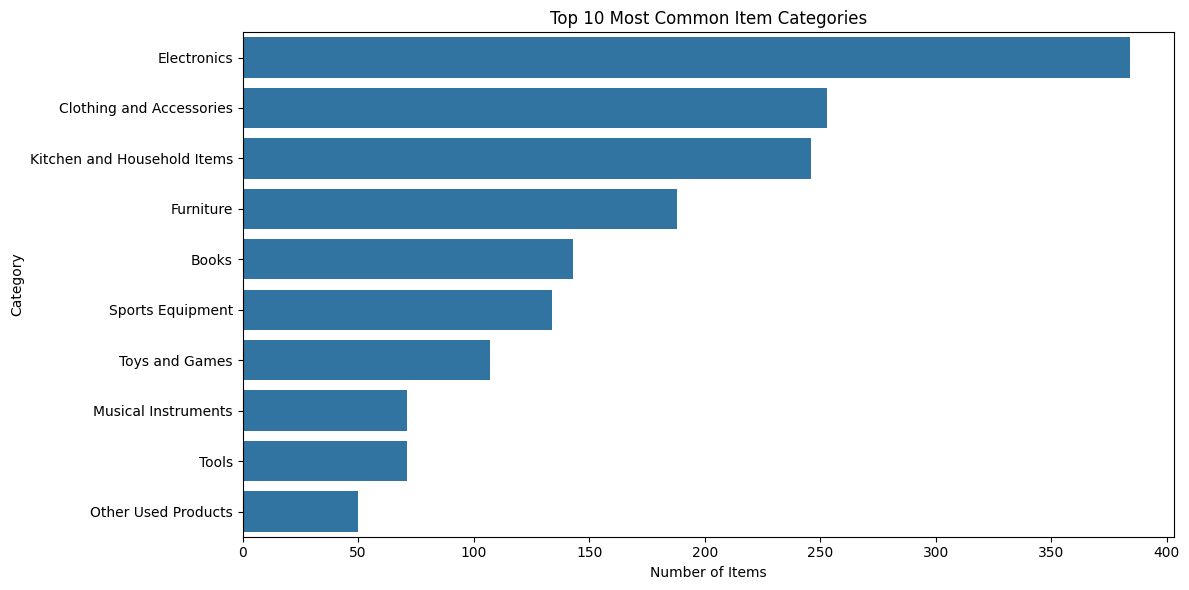

In [23]:
plt.figure(figsize=(12, 6))

top_categories = clean_df["category"].value_counts().head(10)

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top 10 Most Common Item Categories")
plt.xlabel("Number of Items")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

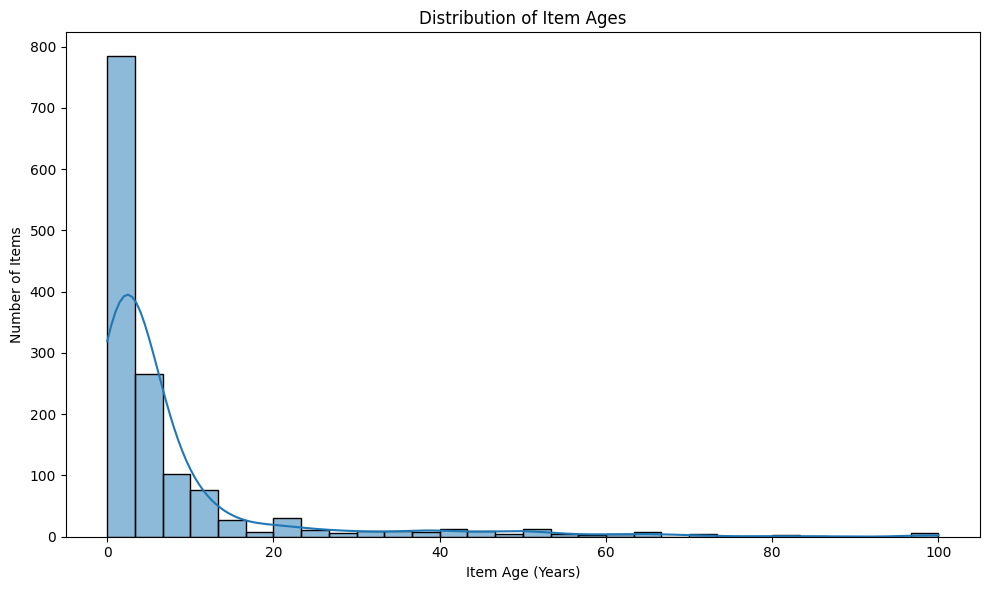

In [24]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=clean_df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Distribution of Item Ages")
plt.xlabel("Item Age (Years)")
plt.ylabel("Number of Items")
plt.tight_layout()
plt.show()

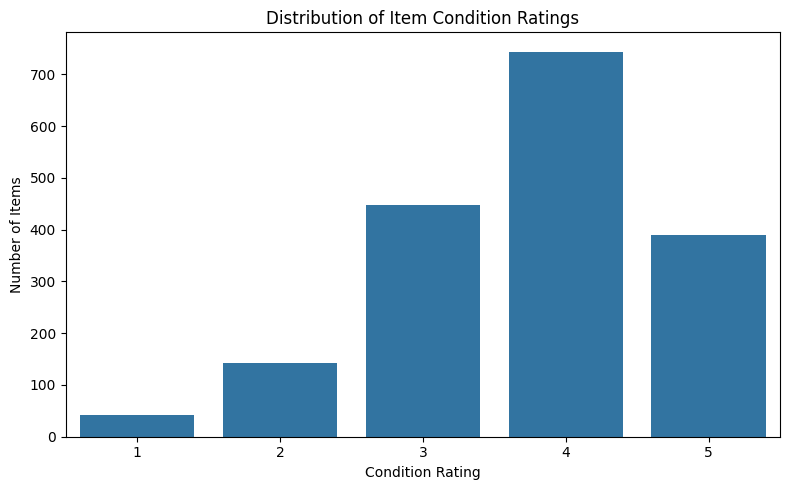

In [25]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_df,
    x=clean_df["condition"].dropna().astype(int),
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Item Condition Ratings")
plt.xlabel("Condition Rating")
plt.ylabel("Number of Items")
plt.tight_layout()
plt.show()

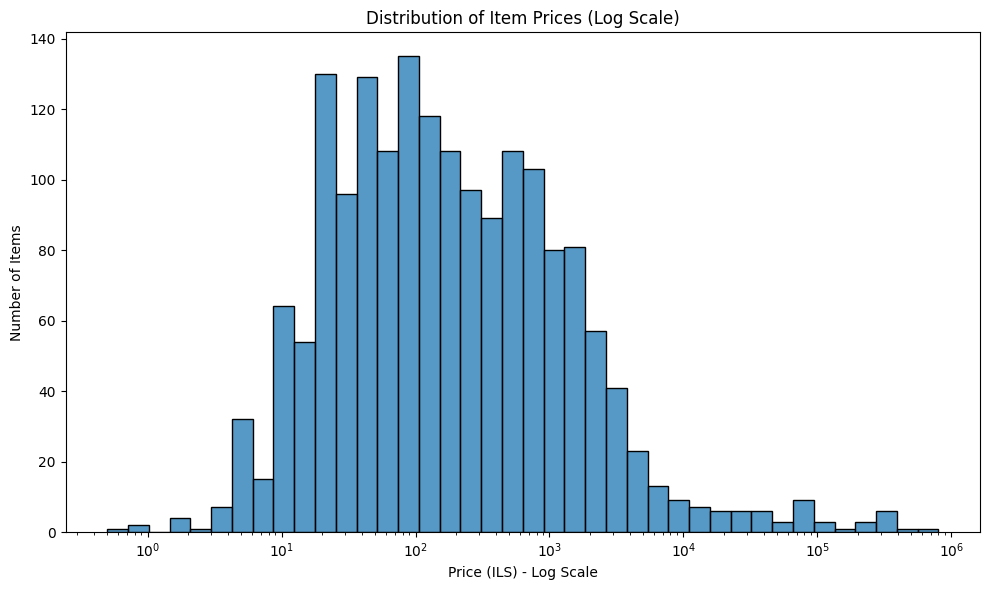

In [26]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=clean_df,
    x="price_ils",
    bins=40,
    log_scale=True
)

plt.title("Distribution of Item Prices (Log Scale)")
plt.xlabel("Price (ILS) - Log Scale")
plt.ylabel("Number of Items")
plt.tight_layout()
plt.show()

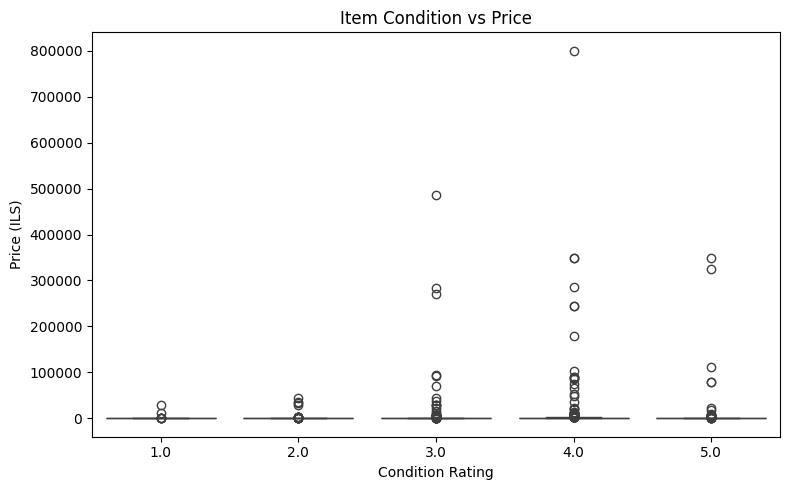

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=clean_df,
    x="condition",
    y="price_ils"
)

plt.title("Item Condition vs Price")
plt.xlabel("Condition Rating")
plt.ylabel("Price (ILS)")

plt.tight_layout()
plt.show()

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("marketplace_cleaned.csv")

print(df.shape)
print(df.columns.tolist())
df.head()

(1801, 20)
['global_id', 'student_id', 'source_file', 'item_id', 'title', 'description', 'category', 'age', 'condition', 'price', 'currency', 'item_photo', 'image_path', 'invalid_price', 'invalid_age', 'invalid_condition', 'price_ils', 'price_outlier', 'age_outlier', 'price_vs_category_median']


,global_id,student_id,source_file,item_id,title,description,category,age,condition,price,currency,item_photo,image_path,invalid_price,invalid_age,invalid_condition,price_ils,price_outlier,age_outlier,price_vs_category_median
0,1,1210482,1210482.csv,1,Tesla Model 3,"standard range with 21,867 miles on it. Deep B...",Cars,4.0,4.0,28868.0,USD,NaN,images/0001_1210482.jpg,False,False,False,103924.8,high,normal,0.40
1,2,1210482,1210482.csv,2,Mercedes-Benz AMG GT 63 4MATIC,22025 miles on it. Obsidian Black Metallic ext...,Cars,7.0,4.0,79412.0,USD,NaN,images/0002_1210482.jpg,False,False,False,285883.2,high,normal,1.11
2,3,1210482,1210482.csv,3,Lexus LX 600 Luxury,11956 miles on it. Eminent White Pearl exterio...,Cars,3.0,5.0,90451.0,USD,NaN,images/0003_1210482.jpg,False,False,False,325623.6,high,normal,1.26
3,4,1210482,1210482.csv,4,Crate & Barrel Unwind Green Velvet 2 Seater Sofa,Brand: Crate & Barrel. Collection: Unwind. Con...,Furniture,3.0,4.0,750.0,USD,NaN,images/0004_1210482.jpg,False,False,False,2700.0,normal,normal,6.75
4,5,1210482,1210482.csv,5,Drexel Heritage 1980s Postmodern Curved Sofa F...,Brand: Drexel. Condition: Used - Age-worn: Has...,Furniture,40.0,2.0,450.0,USD,NaN,images/0005_1210482.jpg,False,False,False,1620.0,normal,high,4.05


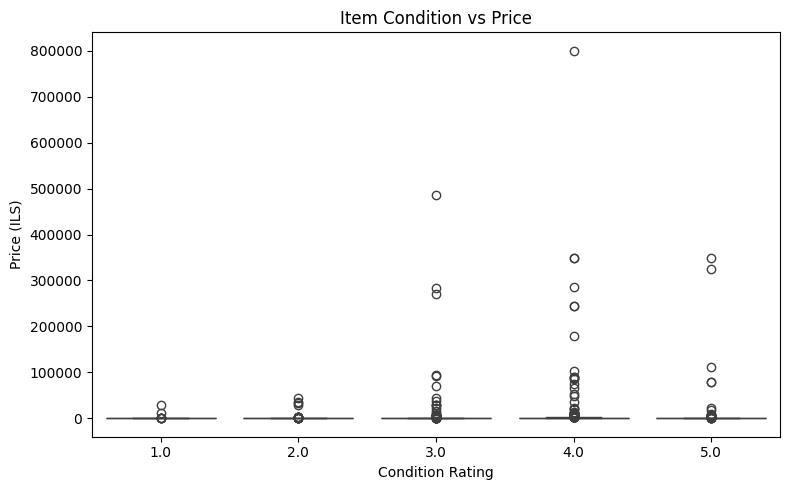

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="condition",
    y="price_ils"
)

plt.title("Item Condition vs Price")
plt.xlabel("Condition Rating")
plt.ylabel("Price (ILS)")

plt.tight_layout()
plt.show()

Items with better condition generally tend to have higher prices, but the relationship is not very strong because the data contains many extreme outliers.

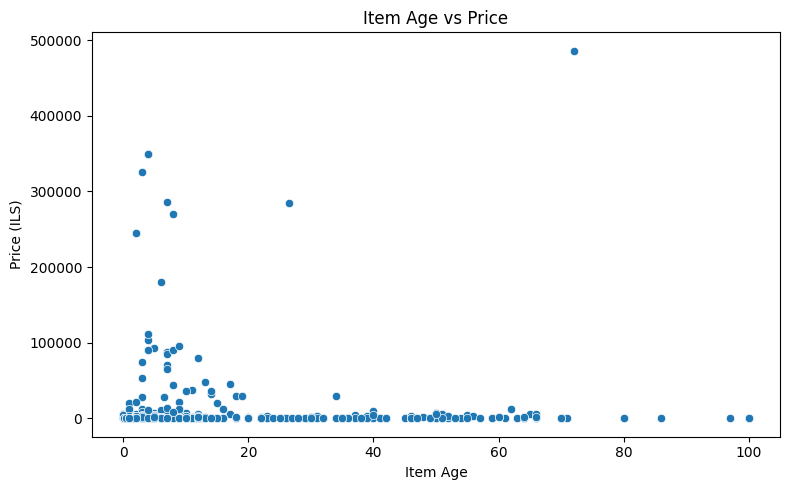

In [30]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="price_ils"
)

plt.title("Item Age vs Price")
plt.xlabel("Item Age")
plt.ylabel("Price (ILS)")

plt.tight_layout()
plt.show()

Item price generally tends to decrease as item age increases. Most older items have relatively low prices, while the highest prices are mainly associated with newer items. However, several extreme price outliers are present.

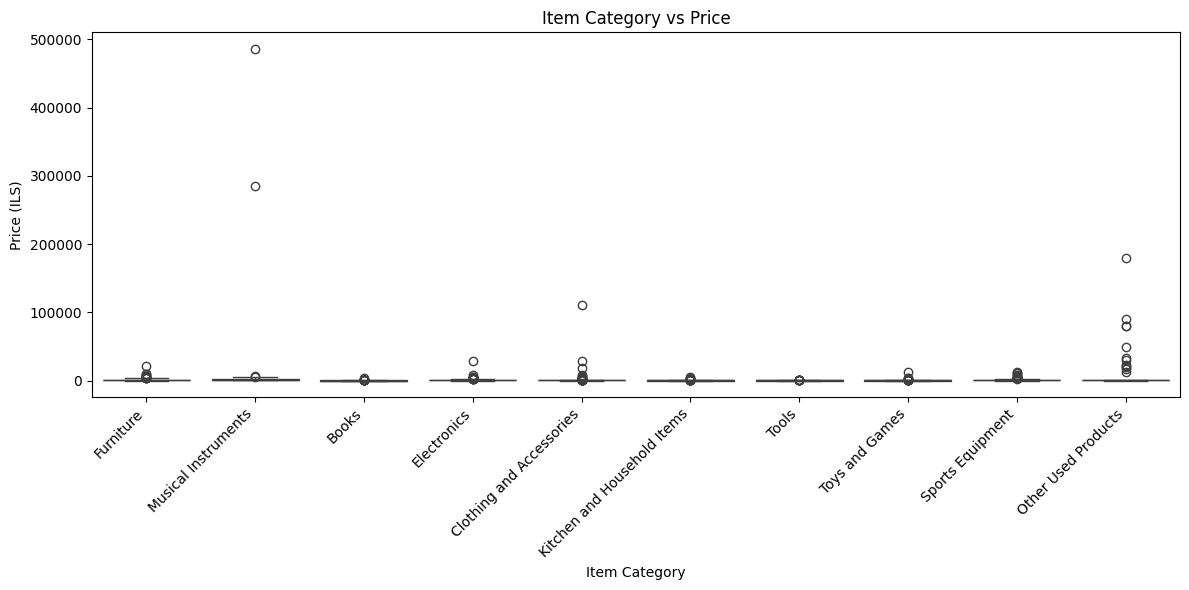

In [31]:
top_categories = df["category"].value_counts().head(10).index

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[df["category"].isin(top_categories)],
    x="category",
    y="price_ils"
)

plt.title("Item Category vs Price")
plt.xlabel("Item Category")
plt.ylabel("Price (ILS)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Item prices vary across categories. Some categories, such as Musical Instruments and Other Used Products, contain much higher price outliers, while most other categories have lower and more concentrated price distributions. This indicates that item category is related to price, although the relationship is influenced by extreme values.

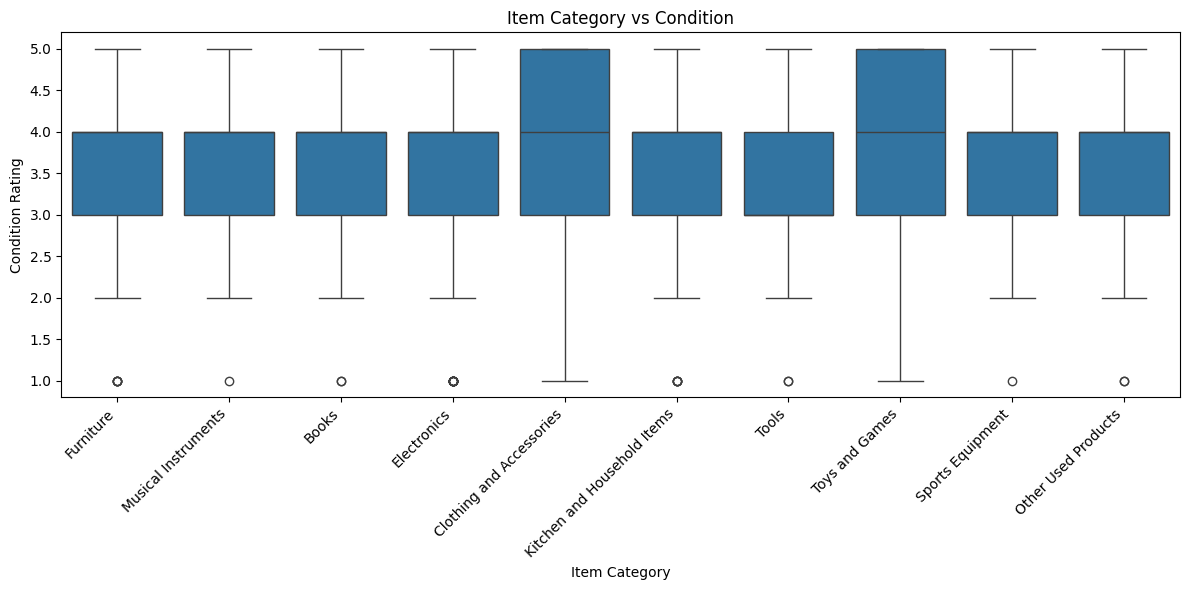

In [32]:
top_categories = df["category"].value_counts().head(10).index

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[df["category"].isin(top_categories)],
    x="category",
    y="condition"
)

plt.title("Item Category vs Condition")
plt.xlabel("Item Category")
plt.ylabel("Condition Rating")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Condition ratings are relatively similar across most item categories, with most values concentrated between 3 and 4. Some categories, such as Clothing and Accessories and Toys and Games, show slightly higher condition ratings, but overall the differences between categories are not very large.

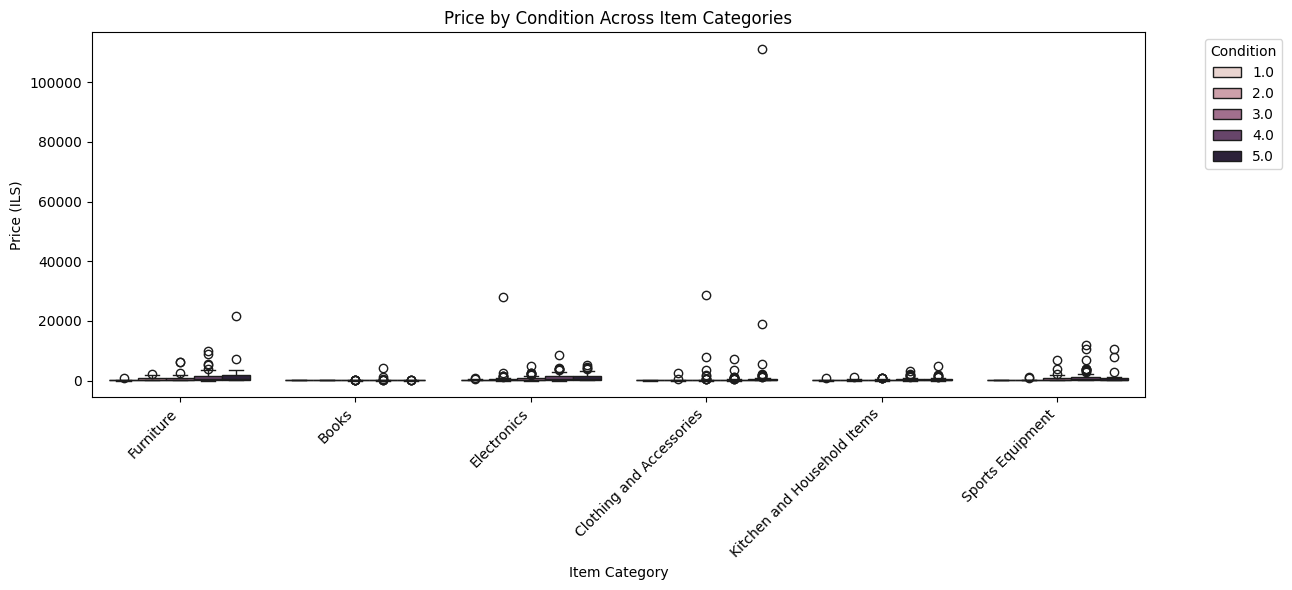

In [33]:
top_categories = df["category"].value_counts().head(6).index

multi_df = df[df["category"].isin(top_categories)].copy()

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=multi_df,
    x="category",
    y="price_ils",
    hue="condition"
)

plt.title("Price by Condition Across Item Categories")
plt.xlabel("Item Category")
plt.ylabel("Price (ILS)")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Condition", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

The relationship between condition and price varies across item categories, but the pattern is not equally strong in all categories. Some categories, such as Clothing and Accessories and Electronics, include higher-priced items at certain condition levels, while other categories show more similar price distributions. Extreme price outliers also influence the comparison.

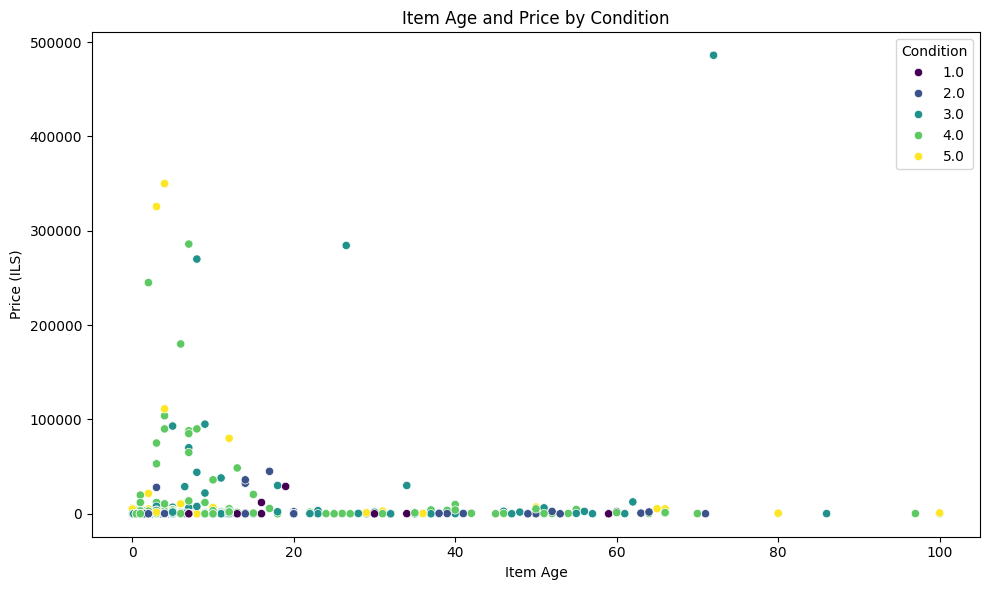

In [34]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="age",
    y="price_ils",
    hue="condition",
    palette="viridis"
)

plt.title("Item Age and Price by Condition")
plt.xlabel("Item Age")
plt.ylabel("Price (ILS)")
plt.legend(title="Condition")

plt.tight_layout()
plt.show()

Most high-priced items are relatively new, while older items generally have lower prices regardless of their condition. Among older items, better condition does not appear to create a strong increase in price. A few extreme outliers are present, but the overall pattern remains the same.

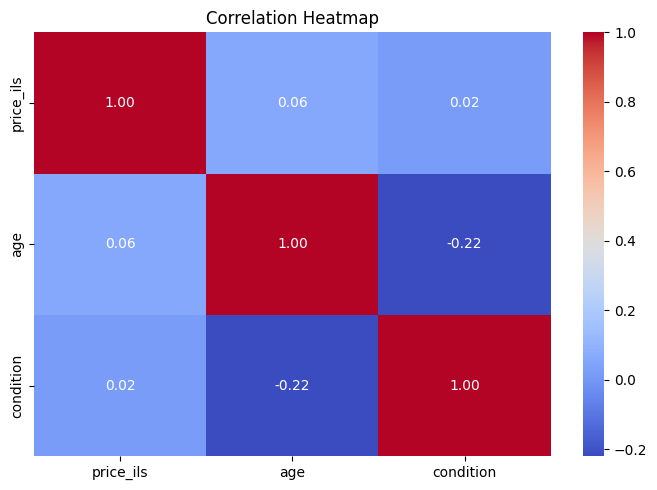

In [35]:
numeric_cols = ["price_ils", "age", "condition"]

corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

The correlation heatmap shows very weak linear relationships between price and the other numerical variables. The correlation between price and age is 0.06, while the correlation between price and condition is 0.02. Age and condition have a weak negative correlation of -0.22, suggesting that older items tend to have slightly lower condition ratings.

## 5. Insight Discovery
### Insight 1: Older items are usually associated with lower prices

**Observed Pattern:**  
Most high-priced items are relatively new, while older items are generally concentrated at lower price levels.

**Evidence:**  
The *Item Age vs Price* scatterplot shows that the highest prices mainly occur among items with low ages. Most items with higher ages are clustered near the lower end of the price scale.

**Meaning:**  
Item age appears to play a role in how sellers value used products, although the relationship is not strongly linear.

**Marketplace Implication:**  
Buyers looking for lower-priced products may find better deals among older items, while sellers of newer items may be able to ask for higher prices.

---

### Insight 2: Condition alone does not strongly determine price

**Observed Pattern:**  
Items with better condition do not always have substantially higher prices.

**Evidence:**  
The *Item Condition vs Price* boxplot shows considerable overlap in prices across condition ratings. In addition, the correlation between condition and price is only **0.02**, indicating almost no linear relationship.

**Meaning:**  
Price is likely influenced by other characteristics such as category, item type, age, or product value rather than condition alone.

**Marketplace Implication:**  
Sellers should not rely only on good condition when setting a high price. Buyers should also consider other characteristics when evaluating whether a listing is fairly priced.

---

### Insight 3: Price behavior differs substantially across item categories

**Observed Pattern:**  
Some categories contain much higher-priced items and greater price variation than others.

**Evidence:**  
The *Item Category vs Price* boxplot shows large differences across categories. Categories such as **Musical Instruments** and **Other Used Products** contain noticeably high price outliers, while many other categories have more concentrated lower prices.

**Meaning:**  
The type of product is an important factor when interpreting prices in the second-hand marketplace.

**Marketplace Implication:**  
Price comparisons should preferably be made within the same category instead of comparing all marketplace items together, since normal price ranges vary greatly between product types.

---

### Insight 4: Older items tend to have slightly poorer condition

**Observed Pattern:**  
As item age increases, condition ratings tend to decrease slightly.

**Evidence:**  
The correlation heatmap shows a correlation of **-0.22** between age and condition. This represents a weak negative relationship.

**Meaning:**  
Aging may be associated with some deterioration in item condition, but age alone does not completely determine the condition of a used item.

**Marketplace Implication:**  
Buyers should inspect both age and condition rather than assuming that every old item is in poor condition. Sellers of older but well-maintained products may also be able to emphasize their condition as a selling point.

---

### Insight 5: Good condition does not strongly increase the price of older items

**Observed Pattern:**  
Among older items, products in better condition do not show a consistently large price advantage over items in poorer condition.

**Evidence:**  
The *Item Age and Price by Condition* scatterplot shows that most older items remain at relatively low prices across different condition ratings. High-priced observations are concentrated mainly among newer items.

**Meaning:**  
For older products, age may limit the price even when the item remains in good condition.

**Marketplace Implication:**  
Sellers of older items may need to set realistic prices even when their products are well maintained. Buyers may also find older items in good condition at relatively affordable prices.

###6. Limitations

1. **Missing Values**  
Some important variables contain missing values, especially item age, price, currency, and condition. These missing values reduce the number of observations available for some analyses and may affect the reliability of the results.

2. **Unequal Category Representation**  
Some item categories contain many observations, while others contain very few. This makes comparisons between categories less balanced because results from larger categories are more stable than those from categories with only a small number of items.

3. **Extreme Price Outliers**  
The dataset contains several very high price values. Although these values were retained when they appeared plausible, they strongly affect visualizations and summary statistics and can make general price patterns harder to observe.

4. **Self-Reported Data**  
The dataset was collected from multiple student submissions, so values such as item age, condition, category, and price may not have been reported in exactly the same way. Even after standardization, some inconsistencies or subjective judgments may remain.

### Future Data Collection Improvements

1. **Use a Standardized Data Entry Form**  
Future data collection should use predefined categories, currency options, condition ratings, and validation rules. This would reduce spelling differences, inconsistent formats, and invalid values.

2. **Require Important Fields**  
Important attributes such as price, currency, age, condition, and category should be mandatory when submitting an item. This would reduce missing values and improve the quality of later analysis.

3. **Collect More Balanced Samples Across Categories**  
Future datasets should aim to include a more balanced number of items from each category. This would make category comparisons more reliable and reduce bias toward the most common item types.